# tertiary-adjunct 01 · Development, 2013-2019

The six trials of the protocol (2 forms × 3 scores) over the development years, at $100,000:
optimized books rebalanced twice a month, whole shares, the fitted spread, square-root impact,
borrow and IBKR per-share commission. Per form, the score with the best development figure is
chosen: net Sharpe ratio for long-short, net information ratio against SPY for long-only.
Nothing here looks at 2020 or later.

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import polars as pl
from tertiary_adjunct import (
    Study,
    choose,
    development,
    doubled_costs,
    psr,
    selection_series,
    sharpe,
)

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_tbl_cols(20)
st = Study()
P = st.p
res = development(st)
DEV = (P["periods"]["start"], P["periods"]["dev_end"])


def row(r, **extra):
    f = r.figures()
    keep = ["form", "score", "ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover_per_year", "cost_drag",
            "market_return", "active_return", "tracking_error", "ir", "relative_drawdown"]
    return {k: f.get(k) for k in keep} | extra


def table(rows):
    return pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(3))

## 1 · The six trials

In [2]:
table([row(r) for r in res.values()])

form,score,ann_return,ann_vol,sharpe,max_drawdown,turnover_per_year,cost_drag,market_return,active_return,tracking_error,ir,relative_drawdown
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""long_short""","""C1""",0.017,0.085,0.239,-0.182,14.208,0.018,null,null,null,null,null
"""long_short""","""C2""",0.036,0.096,0.414,-0.219,14.226,0.018,null,null,null,null,null
"""long_short""","""C3""",0.039,0.1,0.436,-0.231,12.921,0.017,null,null,null,null,null
"""long_only""","""C1""",0.13,0.148,0.904,-0.234,6.09,0.004,0.142,-0.011,0.055,-0.135,-0.164
"""long_only""","""C2""",0.095,0.145,0.697,-0.232,6.378,0.004,0.142,-0.047,0.052,-0.757,-0.29
"""long_only""","""C3""",0.104,0.143,0.763,-0.243,5.087,0.003,0.142,-0.038,0.049,-0.636,-0.241


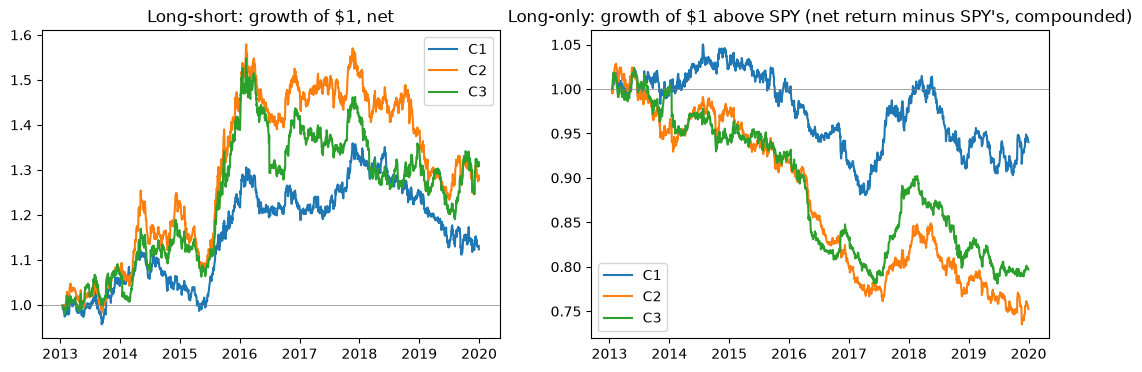

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (form, score), r in res.items():
    s = selection_series(r)
    ax = axes[0 if form == "long_short" else 1]
    ax.plot(s["date"], (1 + s["r"]).cum_prod(), label=score)
axes[0].set_title("Long-short: growth of $1, net")
axes[1].set_title("Long-only: growth of $1 above SPY (net return minus SPY's, compounded)")
for ax in axes:
    ax.axhline(1, color="grey", lw=0.5)
    ax.legend()
plt.show()

## 2 · The choice and the deflated Sharpe ratio

The deflated Sharpe ratio is the probability that the chosen trial's true Sharpe ratio (information ratio for long-only) beats what the best of three trials would show by luck, given its length, skewness and kurtosis. The protocol asks for at least 0.90.

In [4]:
chosen = choose(res)
table([{"form": f, "chosen": c["score"], "figure": c["figure"], "deflated_sharpe": c["deflated_sharpe"],
        "psr_no_deflation": psr(selection_series(res[(f, c["score"])])["r"]),
        **{f"trial_{k}": v for k, v in c["trials"].items()}} for f, c in chosen.items()])

form,chosen,figure,deflated_sharpe,psr_no_deflation,trial_C1,trial_C2,trial_C3
str,str,f64,f64,f64,f64,f64,f64
"""long_only""","""C1""",-0.135,0.137,0.361,-0.135,-0.757,-0.636
"""long_short""","""C3""",0.436,0.816,0.873,0.239,0.414,0.436


## 3 · Robustness of the chosen trials

The protocol asks that the development figure stays positive with execution two days after the signal and with every cost doubled. Also shown, for information only: market-on-close fills paying no half-spread (`auction=True`), fractional shares, and no commission.

In [5]:
rows = []
for form, c in chosen.items():
    base = res[(form, c["score"])]
    variants = {
        "protocol": base,
        "lag 2": st.backtest(form, c["score"], *DEV, lag=2),
        "auction fills": st.backtest(form, c["score"], *DEV, cost_kw={"auction": True}),
        "fractional shares": st.backtest(form, c["score"], *DEV, rounded=False),
    }
    for name, r in variants.items():
        rows.append({"form": form, "score": c["score"], "case": name, "figure": sharpe(selection_series(r)["r"]),
                     "ann_return": r.figures()["ann_return"]})
    doubled = replace(base, daily=doubled_costs(base.daily))
    rows.append({"form": form, "score": c["score"], "case": "costs x2", "figure": sharpe(selection_series(doubled)["r"]),
                 "ann_return": doubled.figures()["ann_return"]})
    free = base.daily.with_columns((pl.col("net") + pl.col("commission_frac")).alias("net"))
    nocomm = replace(base, daily=free)
    rows.append({"form": form, "score": c["score"], "case": "no commission", "figure": sharpe(selection_series(nocomm)["r"]),
                 "ann_return": nocomm.figures()["ann_return"]})
robust = table(rows)
robust

form,score,case,figure,ann_return
str,str,str,f64,f64
"""long_only""","""C1""","""protocol""",-0.135,0.13
"""long_only""","""C1""","""lag 2""",-0.129,0.13
"""long_only""","""C1""","""auction fills""",-0.111,0.132
"""long_only""","""C1""","""fractional shares""",-0.126,0.131
"""long_only""","""C1""","""costs x2""",-0.204,0.126
"""long_only""","""C1""","""no commission""",-0.096,0.133
"""long_short""","""C3""","""protocol""",0.436,0.039
"""long_short""","""C3""","""lag 2""",0.427,0.038
"""long_short""","""C3""","""auction fills""",0.481,0.044


## 4 · Where the costs go

Annual cost as a share of the book: the engine's trading cost (half-spread and impact), borrow on shorts, and IBKR commission; orders and commission dollars per rebalance.

In [6]:
crow = []
for form, c in chosen.items():
    r = res[(form, c["score"])]
    yrs = r.daily.height / 252
    crow.append({"form": form, "score": c["score"], "spread_and_impact": r.daily["cost"].sum() / yrs,
                 "borrow": r.daily["borrow"].sum() / yrs, "commission": r.daily["commission_frac"].sum() / yrs,
                 "orders_per_rebalance": r.commission["orders"].mean(), "commission_usd_per_rebalance": r.commission["commission"].mean(),
                 "names": r.weights.group_by("date").len()["len"].mean(),
                 "turnover_per_rebalance": r.diag["turnover"].mean()})
table(crow)

form,score,spread_and_impact,borrow,commission,orders_per_rebalance,commission_usd_per_rebalance,names,turnover_per_rebalance
str,str,f64,f64,f64,f64,f64,f64,f64
"""long_only""","""C1""",0.002,0.0,0.002,37.701,13.737,43.359,0.253
"""long_short""","""C3""",0.006,0.003,0.007,107.204,38.808,121.695,0.537


## 5 · By year

In [7]:
out = []
for form, c in chosen.items():
    r = res[(form, c["score"])]
    d = r.daily.join(r.market.select("date", "ret"), on="date", how="left")
    y = (d.group_by(pl.col("date").dt.year().alias("year"))
         .agg(((1 + pl.col("net")).product() - 1).alias("net"), ((1 + pl.col("ret")).product() - 1).alias("spy"))
         .sort("year").with_columns(pl.lit(form).alias("form"), pl.lit(c["score"]).alias("score")))
    out.append(y)
pl.concat(out).with_columns((pl.col("net") - pl.col("spy")).alias("net_minus_spy")).select(
    "form", "score", "year", "net", "spy", "net_minus_spy").with_columns(pl.col(pl.Float64).round(3))

form,score,year,net,spy,net_minus_spy
str,str,i32,f64,f64,f64
"""long_only""","""C1""",2013,0.269,0.281,-0.012
"""long_only""","""C1""",2014,0.169,0.135,0.035
"""long_only""","""C1""",2015,-0.015,0.012,-0.027
"""long_only""","""C1""",2016,0.025,0.12,-0.095
"""long_only""","""C1""",2017,0.296,0.217,0.079
"""long_only""","""C1""",2018,-0.097,-0.046,-0.052
"""long_only""","""C1""",2019,0.336,0.312,0.023
"""long_short""","""C3""",2013,0.071,0.281,-0.21
"""long_short""","""C3""",2014,0.085,0.135,-0.05


## 6 · The books

Per rebalance, before rounding: names, forecast volatility (tracking error against the top-500 benchmark for long-only), predicted beta (active beta for long-only) and gross.

In [8]:
drow = []
for form, c in chosen.items():
    dg = res[(form, c["score"])].diag
    drow.append({"form": form, "score": c["score"], "rebalances": dg.height,
                 "relaxed": int((dg["relaxed"] != "none").sum()), "names_before_rounding": dg["names"].mean(),
                 "forecast_vol_or_te": dg["vol"].mean(), "beta": dg["beta"].mean(),
                 "gross": dg["gross"].mean(), "solve_seconds": dg["seconds"].mean()})
table(drow)

form,score,rebalances,relaxed,names_before_rounding,forecast_vol_or_te,beta,gross,solve_seconds
str,str,i64,i64,f64,f64,f64,f64,f64
"""long_only""","""C1""",167,0,46.539,0.05,1.071,1.0,0.127
"""long_short""","""C3""",167,0,129.545,0.078,-0.046,2.0,0.142


## 7 · Where development leaves each form

**Neither form passes the development gate, so neither can pass the protocol, whatever the holdout shows.**

- **Long-short: C3 is chosen.**
  - Net Sharpe 0.44 (C2 0.41, C1 0.24).
  - It holds up with lag 2 (0.43) and with doubled costs (0.27).
  - But its deflated Sharpe ratio is 0.82, under the 0.90 the protocol asks for. Even before deflation the probability is only 0.87. Seven years at a 0.44 Sharpe ratio cannot be told apart from zero.
  - The return came mostly in 2015 (+20%). 2016-2019 were +1.7%, 0.1%, -4.8% and -3.2%.
  - The book sat at the edge of its beta limit (average predicted beta -0.046 against a floor of -0.05): the scores prefer low-beta names.
- **Long-only: every score trailed SPY after costs.**
  - C1 lost least: -1.1%/yr, information ratio -0.13. C2 was -4.7%/yr and C3 -3.8%/yr.
  - C1's deflated Sharpe ratio is 0.14, and C1 stays negative with lag 2 and with doubled costs.
  - Tilting toward value and quality inside large caps cost money while large-cap growth led.
- **Costs at $100k.**
  - Long-short turns over about 13 times a year and pays about 1.6%/yr: 0.6% half-spread and impact, 0.3% borrow, and 0.7% IBKR commission (about 107 orders, $39, per rebalance). Without commission its Sharpe ratio would be 0.51.
  - Long-only pays about 0.4%/yr.
- **Whole shares cost almost nothing.** Fractional shares change either figure by less than 0.01. Auction fills that pay no half-spread add 0.02-0.05.